Installation and Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

Load and clean the dataset

In [2]:
excel_path = "/content/FinalDataNN.xlsx"
df = pd.read_excel(excel_path)

df_cleaned = df.dropna(subset=["P", "Y", "Ptest", "Ytest"])

P_train = df_cleaned["P"].values.astype("float32")
Y_train = df_cleaned["Y"].values.astype("float32")
P_test = df_cleaned["Ptest"].values.astype("float32")
Y_test = df_cleaned["Ytest"].values.astype("float32")

print(f"Train set size: {len(P_train)} samples")
print(f"Test set size: {len(P_test)} samples")

Train set size: 1072 samples
Test set size: 1072 samples


Hyper-parameters

In [3]:
K_S        = 5   # k: Spline order
G_S        = 3   # g: Grid size
IMIN       = 0.0 # NOTE: ReLU-KAN's basis grid is fixed to [0, 1] by construction
IMAX       = 1.0 #       (see quiqi/relu_kan) -- kept here only as a reminder to
                  #       scale P/Y into this range before training.
Batch_Size  = 32
Context_Len = 120
Pred_Len    = 20
H_Dims      = 32
N_Epochs    = 1500
Learning_Rate = 3e-4
Seq_Step = 5
Num_Layers  = 2
Bidirectional = False

Displaying Time Series

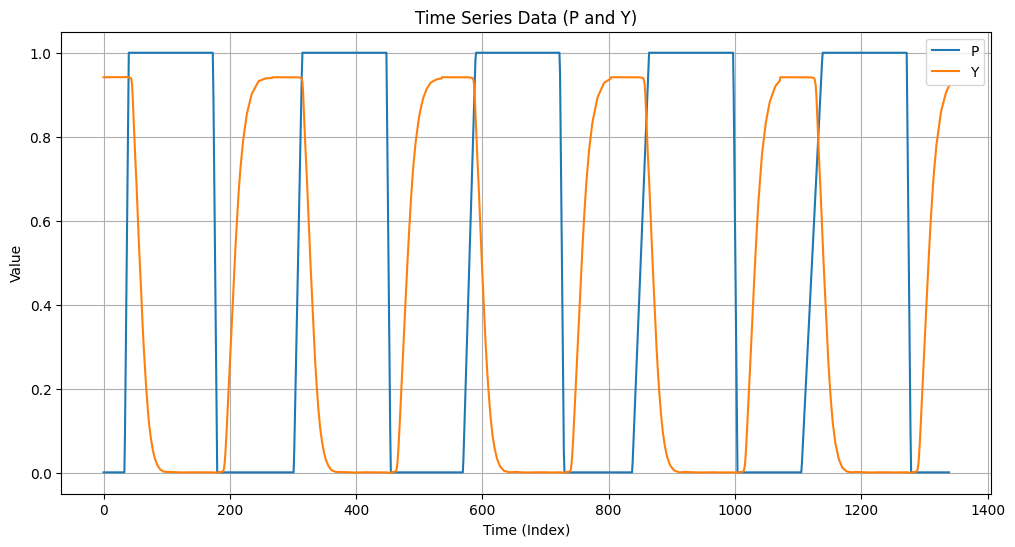

In [4]:
time_series_data_P = df["P"]
time_series_data_Y = df["Y"]

plt.figure(figsize=(12, 6))
plt.plot(time_series_data_P, label="P")
plt.plot(time_series_data_Y, label="Y")
plt.title("Time Series Data (P and Y)")
plt.xlabel("Time (Index)")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

Sliding-window dataset (P → Y)

In [5]:
class PairedTimeSeriesDataset(Dataset):
    def __init__(self, x_series, y_series, context_len=Context_Len, pred_len=Pred_Len):
        self.x = torch.tensor(x_series, dtype=torch.float32)
        self.y = torch.tensor(y_series, dtype=torch.float32)
        self.context_len = context_len
        self.pred_len = pred_len
        self.total_len = context_len + pred_len
        self.n_samples = max(len(self.x) - self.total_len + 1, 0)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        x_win = self.x[idx: idx + self.context_len]
        y_win = self.y[idx + self.context_len: idx + self.total_len]
        return x_win, y_win

train_dataset = PairedTimeSeriesDataset(P_train, Y_train)
test_dataset = PairedTimeSeriesDataset(P_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=Batch_Size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=Batch_Size, shuffle=False)

print(f"Train windows: {len(train_dataset)}")
print(f"Test windows: {len(test_dataset)}")

Train windows: 933
Test windows: 933


ReLU-KAN layer

In [6]:
class ReLUKANLayer(nn.Module):
    """
    ReLU-KAN basis layer -- ported from https://github.com/quiqi/relu_kan
    (torch_relu_kan.py). Grid, `r`, and the basis formula are identical to
    upstream; domain is fixed to [0, 1] by construction (no imin/imax).
    """
    def __init__(self, input_size: int, g: int, k: int, output_size: int, train_ab: bool = True):
        super().__init__()
        self.g, self.k, self.r = g, k, 4 * g * g / ((k + 1) * (k + 1))
        self.input_size, self.output_size = input_size, output_size

        phase_low = np.arange(-k, g) / g
        phase_height = phase_low + (k + 1) / g

        self.phase_low = nn.Parameter(
            torch.Tensor(np.array([phase_low for _ in range(input_size)])),
            requires_grad=train_ab
        )
        self.phase_height = nn.Parameter(
            torch.Tensor(np.array([phase_height for _ in range(input_size)])),
            requires_grad=train_ab
        )
        self.equal_size_conv = nn.Conv2d(1, output_size, (g + k, input_size))

    def forward(self, x):
        # x: (batch, input_size)
        # NOTE: the only deviation from upstream -- explicit broadcasting so this
        # works for input_size > 1 (upstream's raw `x - self.phase_low` only
        # broadcasts correctly when input_size == 1).
        x_expanded = x.unsqueeze(2).expand(-1, -1, self.phase_low.size(1))

        x1 = torch.relu(x_expanded - self.phase_low)
        x2 = torch.relu(self.phase_height - x_expanded)
        x = x1 * x2 * self.r
        x = x * x                     # R_i(x) = [ReLU(x-s_i)*ReLU(e_i-x)*r]^2, same as upstream

        x = x.reshape((len(x), 1, self.g + self.k, self.input_size))
        x = self.equal_size_conv(x)   # upstream's "matrix addition + dot multiplication" trick
        x = x.reshape((len(x), self.output_size))
        return x

class ReLUKAN(nn.Module):
    """Stack of ReLUKANLayer, exactly as upstream's ReLUKAN wrapper."""
    def __init__(self, width, grid, k):
        super().__init__()
        self.rk_layers = nn.ModuleList([
            ReLUKANLayer(width[i], grid, k, width[i + 1])
            for i in range(len(width) - 1)
        ])

    def forward(self, x):
        for rk_layer in self.rk_layers:
            x = rk_layer(x)
        return x

ReLU-KAN recurrent blocks

In [7]:
class ReLUKANRNNCell(nn.Module):
    """
    A genuinely recurrent KAN cell: the hidden-state update
        h_t = ReLUKAN([x_t ; h_{t-1}])
    is computed by a ReLU-KAN layer instead of the Linear + activation used by
    a vanilla RNN cell.
    """
    def __init__(self, input_size, hidden_size, grid, k):
        super().__init__()
        self.hidden_size = hidden_size
        self.rk = ReLUKAN(
            width=[input_size + hidden_size, hidden_size],
            grid=grid,
            k=k
        )

    def forward(self, x_t, h_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        h_t = self.rk(combined)
        return h_t

class ReLUKANRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, grid, k):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = ReLUKANRNNCell(input_size, hidden_size, grid, k)
        self.readout = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        batch_size, seq_len, _ = x.shape
        if h0 is None:
            h_t = torch.zeros(batch_size, self.hidden_size, device=x.device, dtype=x.dtype)
        else:
            h_t = h0

        outputs = []
        for t in range(seq_len):
            h_t = self.cell(x[:, t, :], h_t)   # <-- recurrence: h_t depends on h_{t-1}
            outputs.append(self.readout(h_t).unsqueeze(1))

        outputs = torch.cat(outputs, dim=1)
        return outputs, h_t

Main model: Recurrent ReLU-KAN

In [8]:
class RecurrentReLUKAN(nn.Module):
    def __init__(self, context_len: int, pred_len: int, g: int, k: int, kan_out_dim: int, rnn_hidden: int,
                 seq_step: int = 10):
        super().__init__()
        assert context_len % seq_step == 0, "context_len must be a multiple of seq_step"

        self.context_len = context_len
        self.pred_len = pred_len
        self.seq_step = seq_step
        self.num_steps = context_len // seq_step

        # Shared ReLU-KAN "embedding" applied to every chunk of the window
        self.kan = ReLUKANLayer(
            input_size=seq_step,
            g=g,
            k=k,
            output_size=kan_out_dim,
            train_ab=True
        )

        # Genuine recurrence: a ReLU-KAN-based RNN cell scanned over num_steps
        self.rnn = ReLUKANRNN(
            input_size=kan_out_dim,
            hidden_size=rnn_hidden,
            output_size=rnn_hidden,
            grid=g,
            k=k
        )

        self.fc_out = nn.Linear(rnn_hidden, pred_len)

    def forward(self, x):
        if x.dim() == 2:
            b, L = x.shape
        elif x.dim() == 3 and x.size(-1) == 1:
            x = x.squeeze(-1)
            b, L = x.shape
        else:
            raise ValueError(f"Unsupported input shape {x.shape}")

        assert L == self.context_len, f"Expected context_len={self.context_len}, got {L}"

        x_steps = x.view(b, self.num_steps, self.seq_step)
        kan_out = self.kan(x_steps.reshape(b * self.num_steps, self.seq_step))
        kan_seq = kan_out.view(b, self.num_steps, -1)

        _, h_last = self.rnn(kan_seq)   # scans over num_steps timesteps recurrently
        return self.fc_out(h_last)

Recurrent ReLU-KAN with Global Feedback

In [9]:
class RecurrentReLUKANGlobalFB(nn.Module):
    """
    Global-feedback variant of RecurrentReLUKAN -- no explicit gate.

    Pass 1: scan all chunks with a zero global context -> get h_last (a
             whole-window summary).
    Pass 2: re-scan the SAME chunks, concatenating that summary directly
             (no learnable gate, no sigmoid/tanh scaling) onto every chunk's
             embedding before feeding the RNN -- i.e. the end of the
             sequence feeds back into every earlier step, not just its
             immediate successor (which is all the baseline's local,
             next-step recurrence h_t = ReLUKAN([x_t; h_{t-1}]) does).

    Unlike an LSTM/GRU-style gate, there is nothing here forcing "how much"
    of the global signal to use -- that is left entirely to the ReLU-KAN
    basis inside self.rnn's cell to learn from [chunk_embedding ; h_prev ;
    global_ctx], since ReLU-KAN is a universal function approximator and
    can in principle learn any gating-like behaviour on its own.

    Cost: ~2x the forward compute of the baseline.
    """
    def __init__(self, context_len: int, pred_len: int, g: int, k: int, kan_out_dim: int, rnn_hidden: int,
                 seq_step: int = 10):
        super().__init__()
        assert context_len % seq_step == 0, "context_len must be a multiple of seq_step"

        self.context_len = context_len
        self.pred_len = pred_len
        self.seq_step = seq_step
        self.num_steps = context_len // seq_step
        self.rnn_hidden = rnn_hidden

        # Shared ReLU-KAN "embedding" applied to every chunk of the window
        self.kan = ReLUKANLayer(
            input_size=seq_step,
            g=g,
            k=k,
            output_size=kan_out_dim,
            train_ab=True
        )

        # +rnn_hidden extra input channels carry the broadcast global context
        self.rnn = ReLUKANRNN(
            input_size=kan_out_dim + rnn_hidden,
            hidden_size=rnn_hidden,
            output_size=rnn_hidden,
            grid=g,
            k=k
        )

        self.fc_out = nn.Linear(rnn_hidden, pred_len)

    def _embed(self, x):
        b = x.size(0)
        x_steps = x.view(b, self.num_steps, self.seq_step)
        kan_out = self.kan(x_steps.reshape(b * self.num_steps, self.seq_step))
        return kan_out.view(b, self.num_steps, -1)

    def forward(self, x):
        if x.dim() == 2:
            b, L = x.shape
        elif x.dim() == 3 and x.size(-1) == 1:
            x = x.squeeze(-1)
            b, L = x.shape
        else:
            raise ValueError(f"Unsupported input shape {x.shape}")

        assert L == self.context_len, f"Expected context_len={self.context_len}, got {L}"

        kan_seq = self._embed(x)  # (b, num_steps, kan_out_dim)

        # --- pass 1: no global signal yet, use zeros -> get a whole-window summary ---
        zero_ctx = torch.zeros(b, self.num_steps, self.rnn_hidden, device=x.device, dtype=x.dtype)
        _, h_last = self.rnn(torch.cat([kan_seq, zero_ctx], dim=-1))

        # --- pass 2: broadcast h_last (global feedback) into every step, RAW --
        # (no gate -- the ReLU-KAN cell itself must learn how to weigh this)
        global_ctx = h_last.unsqueeze(1).expand(-1, self.num_steps, -1)
        _, h_last2 = self.rnn(torch.cat([kan_seq, global_ctx], dim=-1))

        return self.fc_out(h_last2)


Training utilities

In [10]:
def mae(y_true, y_pred):
    return torch.mean(torch.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return torch.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return torch.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_total = torch.sum((y_true - torch.mean(y_true)) ** 2)
    ss_residual = torch.sum((y_true - y_pred) ** 2)
    return 1 - (ss_residual / ss_total) if ss_total > 0 else torch.tensor(0.0, device=y_true.device)

def signal_to_noise_ratio(y_true, y_pred):
    # Assuming y_pred is the 'signal' and (y_true - y_pred) is the 'noise'
    signal_power = torch.mean(y_pred ** 2)
    noise_power = torch.mean((y_true - y_pred) ** 2)
    if noise_power == 0:
        return torch.tensor(float('inf'), device=y_true.device)
    return 10 * torch.log10(signal_power / noise_power)

def smape(y_true, y_pred):
    numerator = torch.abs(y_pred - y_true)
    denominator = (torch.abs(y_true) + torch.abs(y_pred)) / 2
    smape_values = torch.where(denominator == 0, torch.tensor(0.0, device=y_true.device), numerator / denominator)
    return torch.mean(smape_values) * 100

def nrmse_range(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_range = torch.max(y_true) - torch.min(y_true)
    return (rmse_val / y_range) * 100 if y_range > 0 else torch.tensor(0.0, device=y_true.device)

def nrmse_std(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_std = torch.std(y_true)
    return (rmse_val / y_std) * 100 if y_std > 0 else torch.tensor(0.0, device=y_true.device)

def pointwise_relative_error(y_true, y_pred):
    err = torch.where(y_true == 0, torch.tensor(0.0, device=y_true.device), torch.abs(y_true - y_pred) / torch.abs(y_true))
    return torch.mean(err) * 100

def compute_stats(loader, model, device):
    model.eval()
    tot_mae, tot_mse, tot_samples = 0.0, 0.0, 0
    y_true_all = []
    y_pred_all = []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_pred = model(x)
            tot_mae += mae(y_pred, y).item() * y.numel()
            tot_mse += mse(y_pred, y).item() * y.numel()
            tot_samples += y.numel()
            y_true_all.append(y.cpu())
            y_pred_all.append(y_pred.cpu())

    y_true_all = torch.cat(y_true_all)
    y_pred_all = torch.cat(y_pred_all)

    final_mae = tot_mae / tot_samples
    final_mse = tot_mse / tot_samples
    final_rmse = torch.sqrt(torch.tensor(final_mse, device=device))

    return final_mae, final_mse, final_rmse, y_true_all, y_pred_all

Device, model, optimizer, criterion

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = RecurrentReLUKANGlobalFB(  # <-- Global Feedback variant
    context_len=Context_Len,
    pred_len=Pred_Len,
    g=G_S,
    k=K_S,
    kan_out_dim=H_Dims,
    rnn_hidden=H_Dims,
    seq_step=Seq_Step
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=Learning_Rate)
criterion = nn.L1Loss()

Using device: cuda


Training loop with timing

In [12]:
train_history = []
test_history = []
train_times = []
infer_times = []
per_iteration_train_times = []
total_train_time = 0.0

for epoch in range(1, N_Epochs + 1):
    epoch_start = time.perf_counter()
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        start_time = time.perf_counter()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        per_iteration_train_times.append(time.perf_counter() - start_time)

    epoch_time = time.perf_counter() - epoch_start
    train_times.append(epoch_time)
    total_train_time += epoch_time

    # compute_stats now returns RMSE and y_true_all, y_pred_all
    train_mae, train_mse, train_rmse_val, _, _ = compute_stats(train_loader, model, device)
    test_mae, test_mse, test_rmse_val, _, _ = compute_stats(test_loader, model, device)

    train_history.append((train_mae, train_mse, train_rmse_val))
    test_history.append((test_mae, test_mse, test_rmse_val))

    infer_start = time.perf_counter()
    # Call compute_stats again, but discard the y_true_all and y_pred_all as we only need timing
    _, _, _, _, _ = compute_stats(test_loader, model, device)
    infer_time = time.perf_counter() - infer_start
    infer_times.append(infer_time)

    print(
        f"Epoch {epoch:04d} | "
        f"Loss {running_loss/len(train_loader.dataset):.6f} | "
        f"Train MAE {train_mae:.6f} | Train MSE {train_mse:.6f} | Train RMSE {train_rmse_val:.6f} | "
        f"Test MAE {test_mae:.6f} | Test MSE {test_mse:.6f} | Test RMSE {test_rmse_val:.6f} | "
        f"Train time {epoch_time:.2f}s | Inference time {infer_time:.2f}s"
    )

Epoch 0001 | Loss 0.349829 | Train MAE 0.246666 | Train MSE 0.151306 | Train RMSE 0.388981 | Test MAE 0.243111 | Test MSE 0.147906 | Test RMSE 0.384586 | Train time 4.57s | Inference time 2.57s
Epoch 0002 | Loss 0.183455 | Train MAE 0.131636 | Train MSE 0.057101 | Train RMSE 0.238958 | Test MAE 0.131205 | Test MSE 0.056837 | Test RMSE 0.238405 | Train time 3.10s | Inference time 2.60s
Epoch 0003 | Loss 0.100900 | Train MAE 0.066324 | Train MSE 0.012236 | Train RMSE 0.110618 | Test MAE 0.067038 | Test MSE 0.012638 | Test RMSE 0.112421 | Train time 2.95s | Inference time 2.64s
Epoch 0004 | Loss 0.052818 | Train MAE 0.043709 | Train MSE 0.005185 | Train RMSE 0.072007 | Test MAE 0.044476 | Test MSE 0.005315 | Test RMSE 0.072906 | Train time 3.03s | Inference time 2.72s
Epoch 0005 | Loss 0.036316 | Train MAE 0.031337 | Train MSE 0.003277 | Train RMSE 0.057241 | Test MAE 0.031161 | Test MSE 0.003298 | Test RMSE 0.057432 | Train time 3.16s | Inference time 2.72s
Epoch 0006 | Loss 0.030997 | T

Final evaluation & speed-up

In [13]:
final_train_mae, final_train_mse, final_train_rmse_tensor, y_true_train_final, y_pred_train_final = compute_stats(train_loader, model, device)
final_test_mae, final_test_mse, final_test_rmse_tensor, y_true_test_final, y_pred_test_final = compute_stats(test_loader, model, device)

final_train_rmse = final_train_rmse_tensor.item()
final_test_rmse = final_test_rmse_tensor.item()

def physics_simulation(x_batch):
    time.sleep(0.0001 * x_batch.shape[0])

physics_start = time.perf_counter()
for x, _ in test_loader:
    physics_simulation(x.to(device))
physics_time = time.perf_counter() - physics_start

avg_infer_time = np.mean(infer_times)
speedup = physics_time / (avg_infer_time * len(test_loader))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

avg_epoch_train_time = np.mean(train_times)

# Calculate all other metrics
train_r2 = r2_score(y_true_train_final, y_pred_train_final).item()
test_r2 = r2_score(y_true_test_final, y_pred_test_final).item()

train_snr = signal_to_noise_ratio(y_true_train_final, y_pred_train_final).item()
test_snr = signal_to_noise_ratio(y_true_test_final, y_pred_test_final).item()

train_smape = smape(y_true_train_final, y_pred_train_final).item()
test_smape = smape(y_true_test_final, y_pred_test_final).item()

train_nrmse_range = nrmse_range(y_true_train_final, y_pred_train_final).item()
test_nrmse_range = nrmse_range(y_true_test_final, y_pred_test_final).item()

train_nrmse_std = nrmse_std(y_true_train_final, y_pred_train_final).item()
test_nrmse_std = nrmse_std(y_true_test_final, y_pred_test_final).item()

train_pt_rel_err = pointwise_relative_error(y_true_train_final, y_pred_train_final).item()
test_pt_rel_err = pointwise_relative_error(y_true_test_final, y_pred_test_final).item()

results_df = pd.DataFrame({
    "Metric": [
        "Train MAE", "Test MAE",
        "Train MSE", "Test MSE",
        "Train RMSE", "Test RMSE",
        "Train R2", "Test R2",
        "Train SNR (dB)", "Test SNR (dB)",
        "Train SMAPE (%)", "Test SMAPE (%)",
        "Train NRMSE, range-normalized (%)", "Test NRMSE, range-normalized (%)",
        "Train NRMSE, std-normalized (%)", "Test NRMSE, std-normalized (%)",
        "[reference only, unstable] Train pointwise rel. error (%)",
        "[reference only, unstable] Test pointwise rel. error (%)",
        "[PLACEHOLDER, not physical] Speedup (sleep-proxy / GFKAN)",
        "Total Training Time (s)",
        "Test Time (s)",
        "Average Epoch Training Time (s)",
        "Per-Iteration Training Time (s)",
        "Total number of trainable parameters",
        "Epochs Run",
        "Structure"
    ],
    "Value": [
        final_train_mae, final_test_mae,
        final_train_mse, final_test_mse,
        final_train_rmse, final_test_rmse,
        train_r2, test_r2,
        train_snr, test_snr,
        train_smape, test_smape,
        train_nrmse_range, test_nrmse_range,
        train_nrmse_std, test_nrmse_std,
        train_pt_rel_err, test_pt_rel_err,
        speedup,
        total_train_time,
        avg_infer_time,
        avg_epoch_train_time,
        np.mean(per_iteration_train_times),
        count_parameters(model),
        N_Epochs,
        str(model)
    ]
})

print("\n--- Summary of Results (Markdown) ---")
print(results_df.to_markdown(index=False))


--- Summary of Results (Markdown) ---
| Metric                                                    | Value                                                                            |
|:----------------------------------------------------------|:---------------------------------------------------------------------------------|
| Train MAE                                                 | 0.002770881147582048                                                             |
| Test MAE                                                  | 0.0024296415955754594                                                            |
| Train MSE                                                 | 6.0724666425301957e-05                                                           |
| Test MSE                                                  | 2.2370217214478542e-05                                                           |
| Train RMSE                                                | 0.007792603224515915         

Plot training history

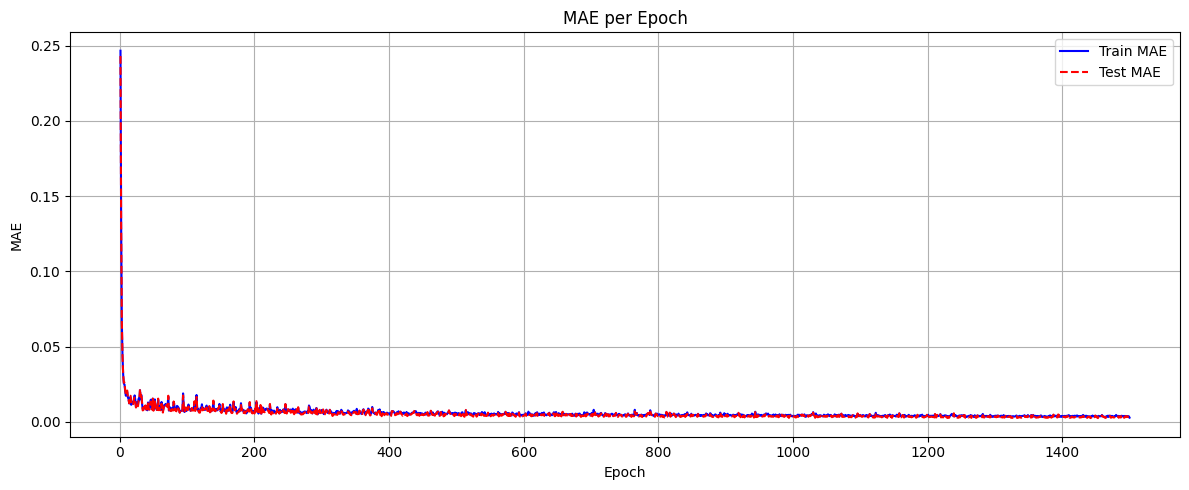

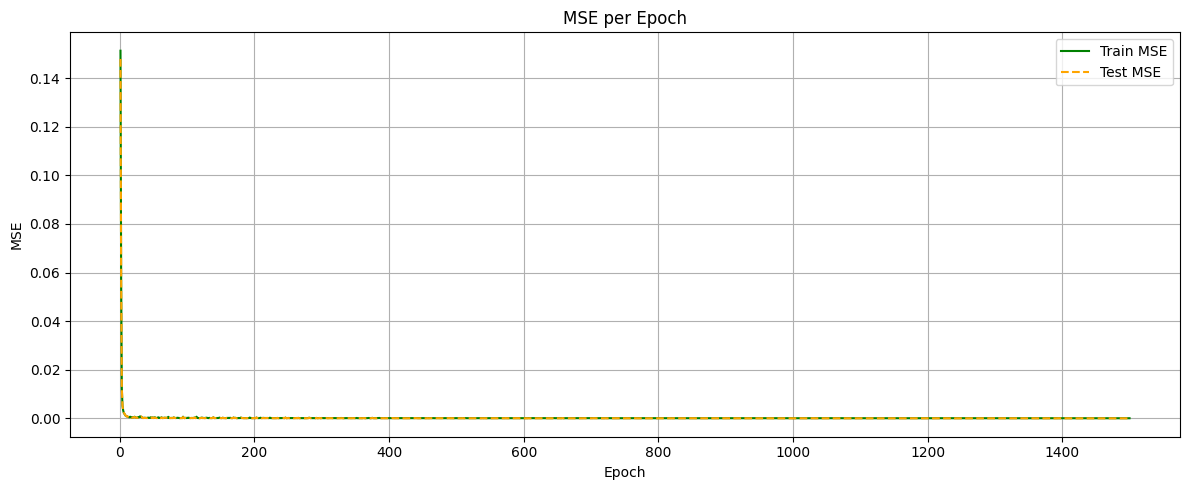

In [14]:
epochs = range(1, N_Epochs + 1)
train_mae_hist = [h[0] for h in train_history]
train_mse_hist = [h[1] for h in train_history]
test_mae_hist = [h[0] for h in test_history]
test_mse_hist = [h[1] for h in test_history]

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mae_hist, label="Train MAE", color="blue")
plt.plot(epochs, test_mae_hist, label="Test MAE", color="red", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("MAE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mse_hist, label="Train MSE", color="green")
plt.plot(epochs, test_mse_hist, label="Test MSE", color="orange", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Full test-set prediction vs ground truth

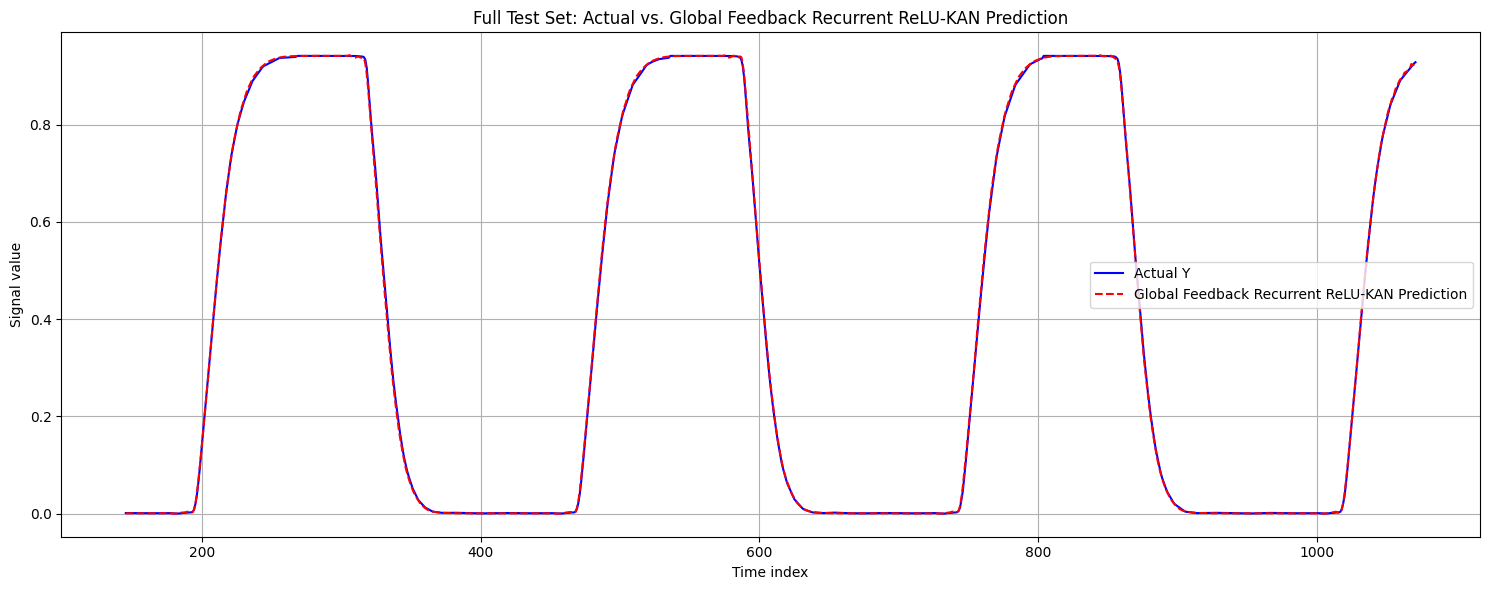

In [16]:
model.eval()
full_predicted_Y_test = np.full_like(Y_test, np.nan, dtype=np.float64)

with torch.no_grad():
    for idx in range(len(test_dataset)):
        x_win, _ = test_dataset[idx]
        x_win = x_win.unsqueeze(0).to(device)
        y_pred_win = model(x_win).cpu().squeeze(0).numpy()

        start_idx = idx + Context_Len
        end_idx = start_idx + Pred_Len
        if start_idx < len(Y_test):
            full_predicted_Y_test[start_idx:min(end_idx, len(Y_test))] = y_pred_win[:min(Pred_Len, len(Y_test) - start_idx)]

start_plot = 145
plt.figure(figsize=(15, 6))
plt.plot(np.arange(start_plot, len(Y_test)), Y_test[start_plot:], label="Actual Y", color="blue")
plt.plot(np.arange(start_plot, len(full_predicted_Y_test)), full_predicted_Y_test[start_plot:],
         label="Global Feedback Recurrent ReLU-KAN Prediction", color="red", linestyle="--")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.title("Full Test Set: Actual vs. Global Feedback Recurrent ReLU-KAN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()